# Digits

# Load data

<a href=https://scikit-learn.org/1.9/modules/generated/sklearn.datasets.load_digits.html#sklearn.datasets.load_digits>url</a>



In [2]:
from sklearn.datasets import load_digits
import numpy as np
import pandas as pd

raw_data = load_digits()
digits_load = load_digits(return_X_y=True, as_frame=True)
data = digits_load[0]
labels = digits_load[1]

data = pd.DataFrame(data)

# labels is a list of integers, we need to reshape it to a 1D array before concatenating with data
labels = np.reshape(labels,(1797,1))

# Print the shape of labels after reshaping
print("Labels shape after reshaping:")
print(f"labels.shape: {labels.shape}")

# Print the shape of data
print("Shape of data before concatenation:", data.shape)
print("data.shape:", data.shape)

# Concatenate data and labels along the last axis
concatenated_data = np.concatenate(
    (data, labels),
    axis=1
)

# Print the shape of concatenated_data after concatenation
print("Shape of concatenated_data after concatenation:")
print(f"concatenated_data.shape: {concatenated_data.shape}")

Labels shape after reshaping:
labels.shape: (1797, 1)
Shape of data before concatenation: (1797, 64)
data.shape: (1797, 64)
Shape of concatenated_data after concatenation:
concatenated_data.shape: (1797, 65)


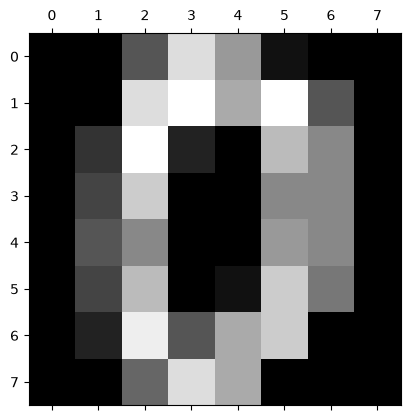

In [3]:
import matplotlib.pyplot as plt
raw_digits = load_digits()
plt.matshow(raw_digits.images[0], cmap="gray")
plt.show()


In [4]:
dataset = pd.DataFrame(concatenated_data)

In [5]:
from collections import deque

def build_variable_corr_by_label(dataset: pd.DataFrame) -> dict:
    variable_corr_by_label = {}
    label_grouped_dataset = dataset.groupby(dataset.columns[-1])
    for label in label_grouped_dataset.groups:
        curr_data = np.array(label_grouped_dataset.get_group(label).values)
        variable_corr_by_label[label] = pd.DataFrame(curr_data[:,0:len(dataset.columns)-1]).corr()
    return variable_corr_by_label

variable_corr_by_label = build_variable_corr_by_label(dataset)
variable_corr_by_label

{0.0:     0         1         2         3         4         5         6   7   8   \
 0  NaN       NaN       NaN       NaN       NaN       NaN       NaN NaN NaN   
 1  NaN  1.000000 -0.006726 -0.075919  0.037607  0.068546 -0.019910 NaN NaN   
 2  NaN -0.006726  1.000000  0.118496 -0.081252  0.096317  0.009403 NaN NaN   
 3  NaN -0.075919  0.118496  1.000000  0.120634 -0.157714 -0.007962 NaN NaN   
 4  NaN  0.037607 -0.081252  0.120634  1.000000  0.554744  0.175502 NaN NaN   
 ..  ..       ...       ...       ...       ...       ...       ...  ..  ..   
 59 NaN -0.056364  0.499327  0.257803  0.053544  0.129560  0.056257 NaN NaN   
 60 NaN  0.065858 -0.373765  0.186431  0.041812 -0.153540 -0.022458 NaN NaN   
 61 NaN  0.081801 -0.262329  0.071365 -0.065372 -0.246890 -0.121933 NaN NaN   
 62 NaN  0.370161 -0.105171 -0.050441 -0.004597 -0.103996 -0.055364 NaN NaN   
 63 NaN       NaN       NaN       NaN       NaN       NaN       NaN NaN NaN   
 
           9   ...        54  55  56        5

Label: 0.0, Number of samples: 178


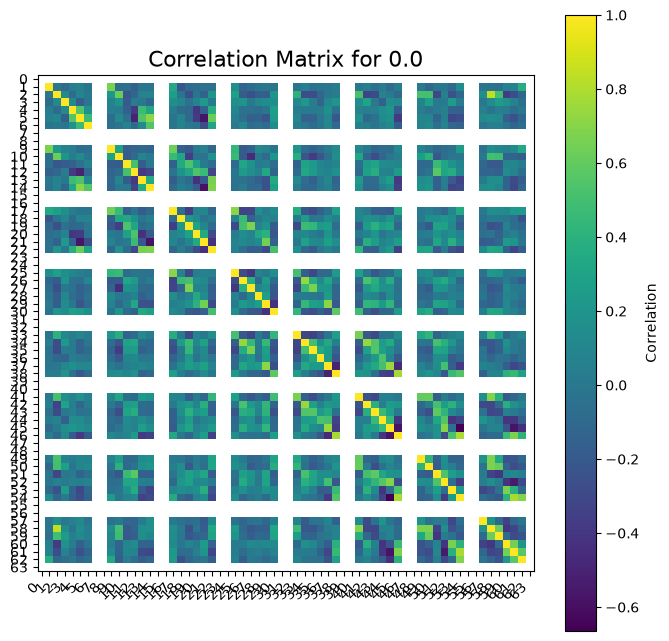

Label: 1.0, Number of samples: 182


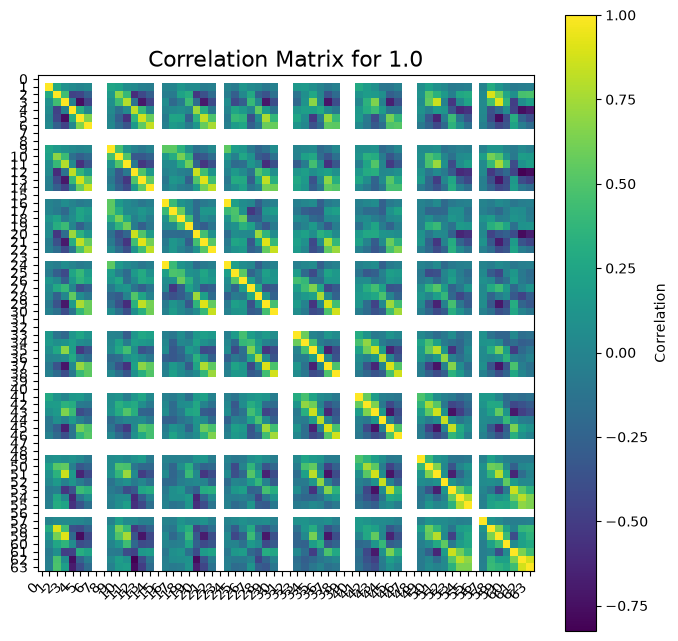

Label: 2.0, Number of samples: 177


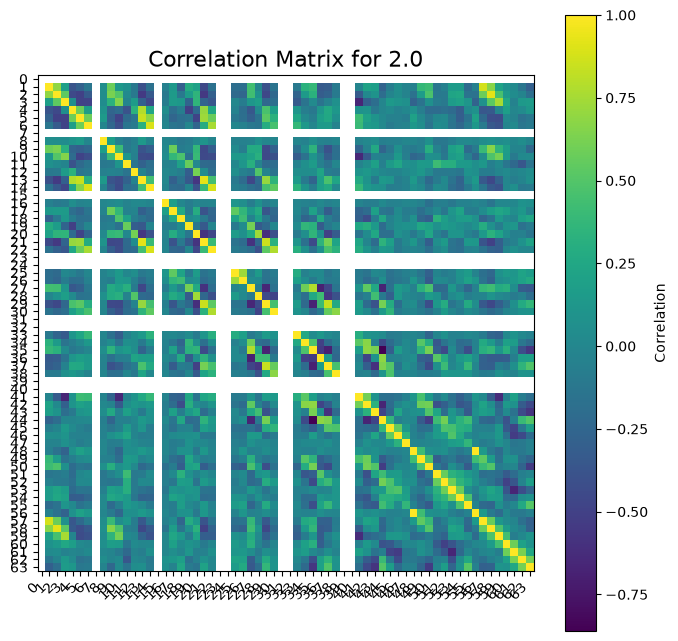

Label: 3.0, Number of samples: 183


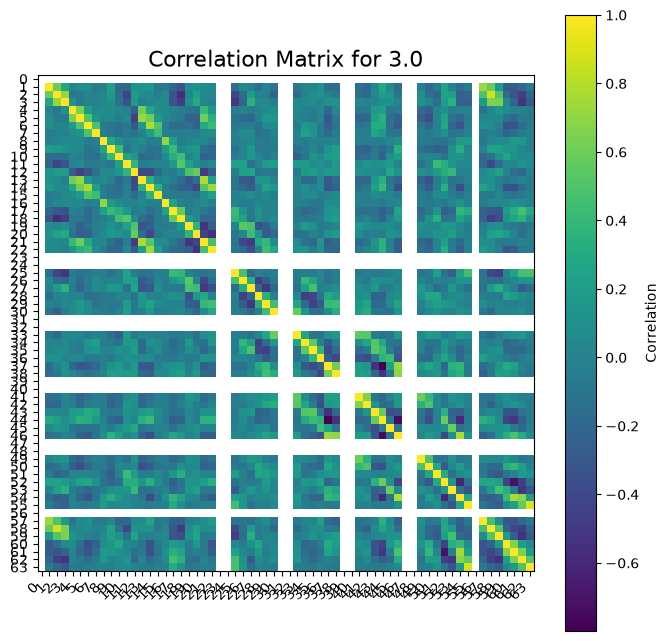

Label: 4.0, Number of samples: 181


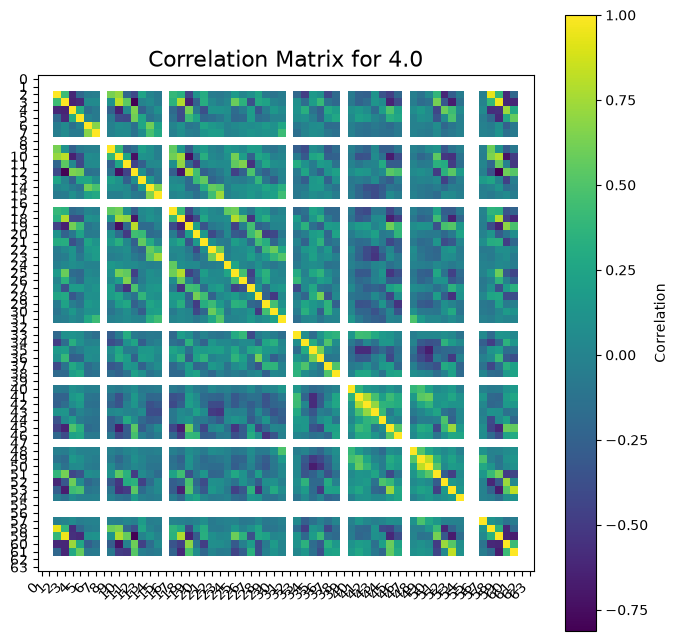

Label: 5.0, Number of samples: 182


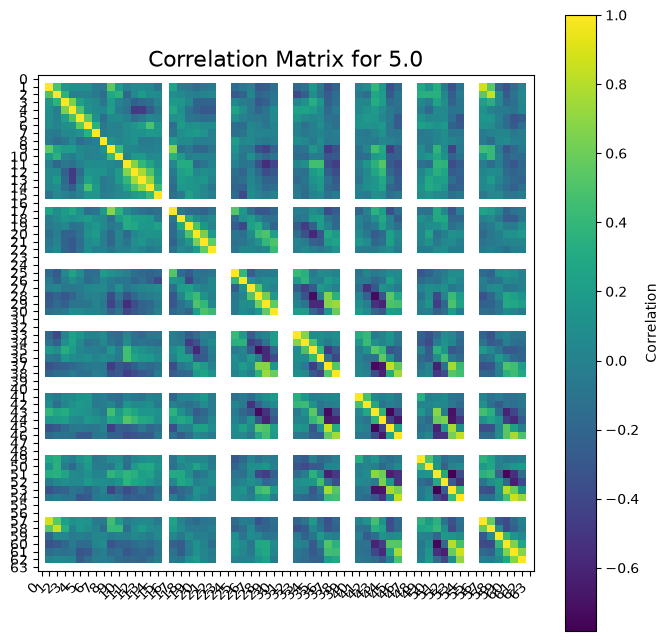

Label: 6.0, Number of samples: 181


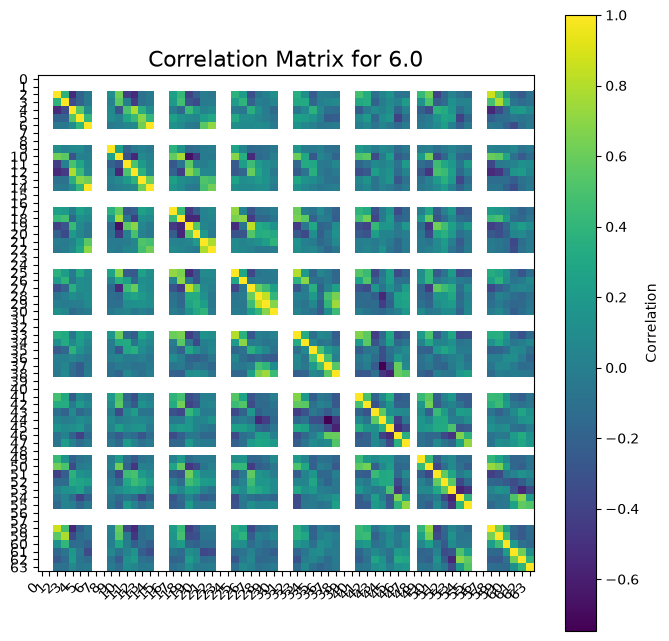

Label: 7.0, Number of samples: 179


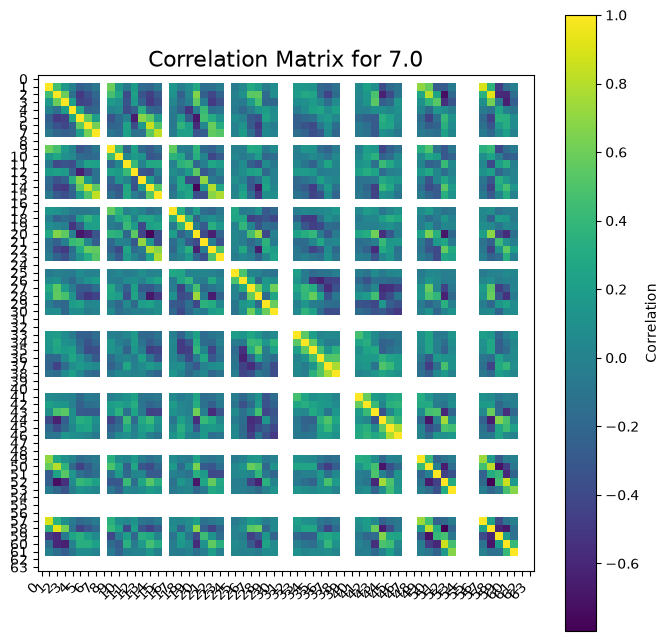

Label: 8.0, Number of samples: 174


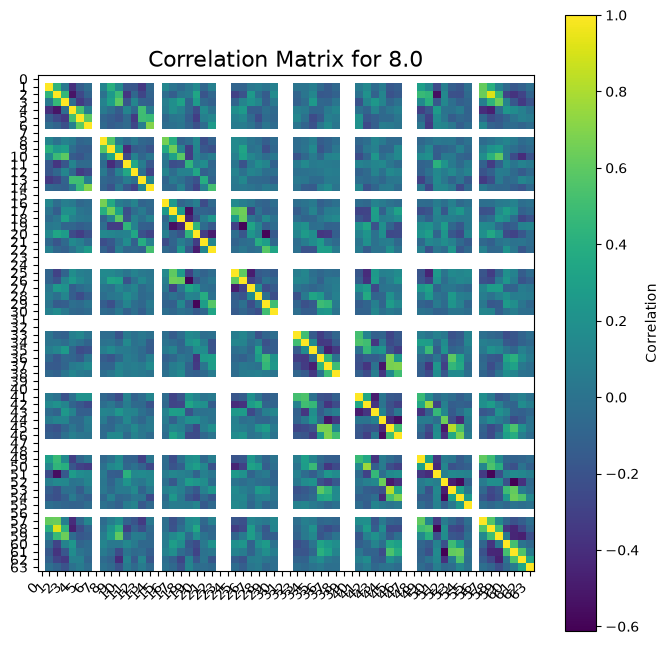

Label: 9.0, Number of samples: 180


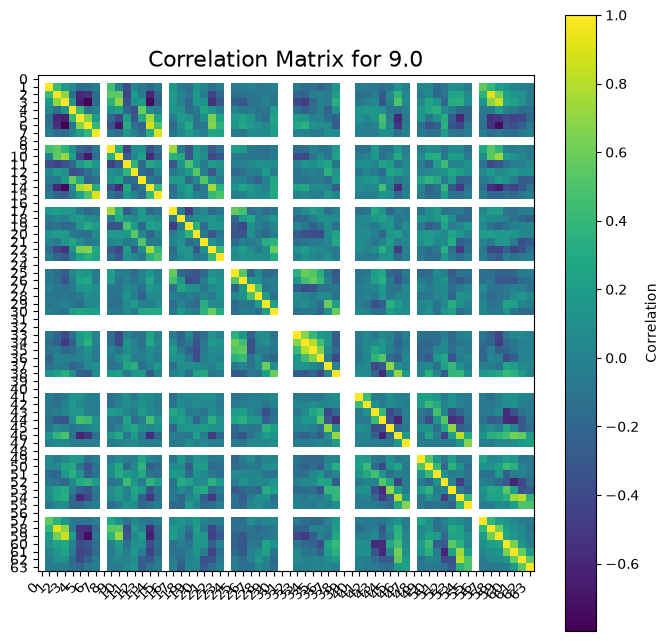

In [23]:
def plot_correlation_matrices(dataset: pd.DataFrame):
    variable_corr_by_label = build_variable_corr_by_label(dataset)
    label_grouped_dataset = dataset.groupby(dataset.columns[-1])
    for label in label_grouped_dataset.groups.keys():
        print(f"Label: {label}, Number of samples: {len(label_grouped_dataset.get_group(label))}")
        df = variable_corr_by_label[label]
        plt.figure(figsize=(8, 8))
        plt.imshow(df, cmap='viridis')
        plt.colorbar(label='Correlation')  # Shows what the colors mean
        plt.title(f"Correlation Matrix for {label}", fontsize=16)
        plt.xticks(ticks=np.arange(len(df.columns)), labels=deque(df.columns), rotation=45, ha='right')
        plt.yticks(ticks=np.arange(len(df.index)), labels=deque(df.index))
        plt.show()

show_plots = True  # Set to True if you want to display the plots
if (show_plots):
    variable_corr_by_label = build_variable_corr_by_label(dataset)
    plot_correlation_matrices(dataset)

# KNN

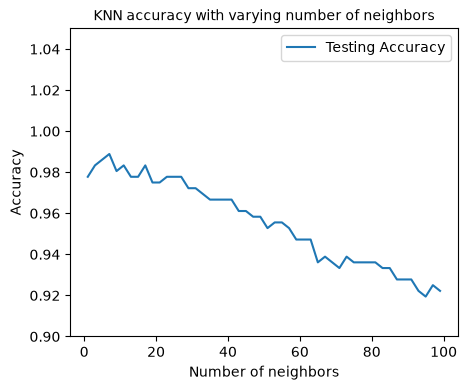

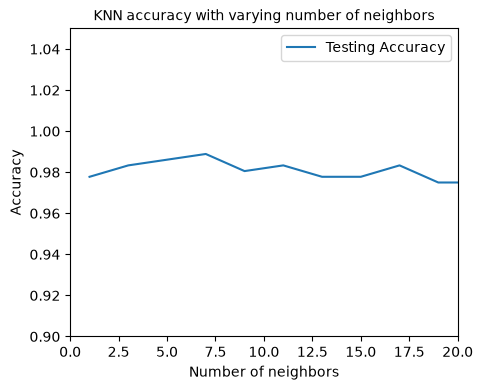

In [7]:
from sklearn.neighbors import KNeighborsClassifier
import numpy as np
from sklearn.model_selection import train_test_split

train_data, test_data, train_label, test_label = train_test_split(dataset.iloc[:,:len(dataset.columns)-1], dataset.iloc[:,len(dataset.columns)-1], test_size=0.2, random_state=42) 

neighbors = np.arange(1, 100, 2)
#train_accuracy = np.zeros(len(neighbors))
test_accuracy = np.zeros(len(neighbors))
for i, k in enumerate(neighbors):
    knn = KNeighborsClassifier(n_neighbors=k)

    #Fit the model
    knn.fit(train_data, train_label)

    #Compute accuracy on the training set
    #train_accuracy[i] = knn.score(train_data, train_label)

    #Compute accuracy on the test set
    test_accuracy[i] = knn.score(test_data, test_label)

plt.figure(figsize=(5,4))
plt.title('KNN accuracy with varying number of neighbors',fontsize=10)
plt.plot(neighbors, test_accuracy, label='Testing Accuracy')
#plt.plot(neighbors, train_accuracy, label='Training accuracy')
plt.legend(prop={'size': 10})
plt.xlabel('Number of neighbors',fontsize=10)
plt.ylabel('Accuracy',fontsize=10)
plt.ylim(0.9, 1.05)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.show()

plt.figure(figsize=(5,4))
plt.title('KNN accuracy with varying number of neighbors',fontsize=10)
plt.plot(neighbors, test_accuracy, label='Testing Accuracy')
#plt.plot(neighbors, train_accuracy, label='Training accuracy')
plt.legend(prop={'size': 10})
plt.xlabel('Number of neighbors',fontsize=10)
plt.ylabel('Accuracy',fontsize=10)
plt.ylim(0.9, 1.05)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.xlim(0, 20)
plt.show()

Correlation matrix analysis complete.


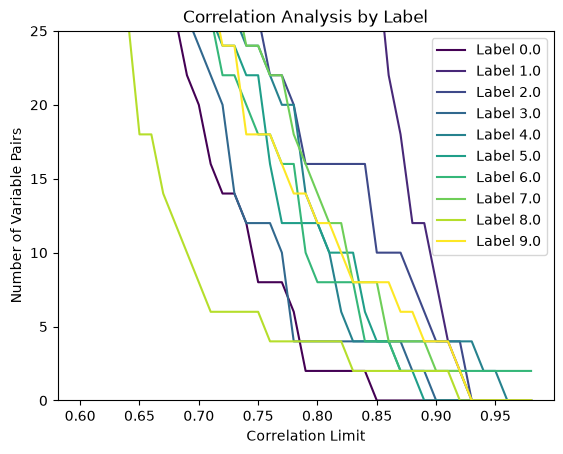

In [22]:
variable_corr_by_label = build_variable_corr_by_label(dataset)

my_correlation_matrix = {}
for label in variable_corr_by_label.keys():
    data_for_label = dataset[dataset.iloc[:,-1] == label]
    #print(f"Label: {label}, Number of samples: {len(data_for_label)}")
    curr_label_corr_matrix = {"limit": [], "num_high_corr_indices": []}
    my_correlation_matrix[label] = curr_label_corr_matrix

    for limit in list(range(60, 99, 1)):     
        limit = limit / 100.0  # Convert to decimal
        curr_label_corr_matrix["limit"].append(limit)
   
        high_corr_indices = np.where((variable_corr_by_label[label].values > limit) & (variable_corr_by_label[label].values < 1))

        # Print the number of highly correlated variable pairs for the current label
        num_high_corr_pairs = len(high_corr_indices[0])
        #print(f"Number of variable pairs with correlation > {limit} for label {label}: {num_high_corr_pairs}")
        curr_label_corr_matrix["num_high_corr_indices"].append(num_high_corr_pairs)

        interested_in_neg_corr = False  # Set to True if you want to check for highly negatively correlated variable pairs
        if interested_in_neg_corr:
            # Print the indices of the variables that have a correlation less than -{limit}
            high_neg_corr_indices = np.where(variable_corr_by_label[label].values < -limit)
            
            # Print the number of highly negatively correlated variable pairs for the current label
            num_high_neg_corr_pairs = len(high_neg_corr_indices[0])
            print(f"Number of variable pairs with correlation < -{limit} for label {label}: {num_high_neg_corr_pairs}")

print("Correlation matrix analysis complete.")
debug = False
if debug:
    print("my_correlation_matrix:")
    for label in my_correlation_matrix.keys():
        corr_data = my_correlation_matrix[label]
        for i in range(len(corr_data["limit"])):
            limit = corr_data["limit"][i]
            num_high_corr_indices = corr_data["num_high_corr_indices"][i]
            print(f"Label: {label}, Correlation limit: {limit}, Number of variable pairs with correlation > {limit}: {num_high_corr_indices}")

# Multi-line plot for the data in my_correlation_matrix
cmap = plt.get_cmap("viridis")
colors = cmap(np.linspace(0, 1, len(my_correlation_matrix)))
plt.gca().set_prop_cycle(color=colors)
for label in my_correlation_matrix.keys():
    # Add a line to the plot for each label
    corr_data = my_correlation_matrix[label]
    plt.plot(corr_data["limit"], corr_data["num_high_corr_indices"], label=f"Label {label}")

plt.xlabel("Correlation Limit")
plt.ylabel("Number of Variable Pairs")
plt.title("Correlation Analysis by Label")
plt.ylim(0, 25)
plt.legend()
plt.show()


Now that I've done this... I think it's backwards.

I've found a way to find pairs of variables that are (variably) strongly (or negatively) correlated for each of the labels.

I think what I really want is to find variables that DON'T correlate with other variables. 

I think this is just going to be a matter of finding the minimums of the sums of the absolute values of the rows or columns of the correlation matrices.